# Understanding the Kalman filter

A **Kalman filter** estimates the hidden **state** of a system (the quantities you care about) from a
stream of **noisy measurements**. Remarkably, it can recover quantities you never measure directly —
velocity from positions, for example — and it reports how confident it is at every step.

The whole filter is defined by just **four matrices**. This notebook builds one from scratch and explains
every idea, using a deliberately plain example: **a point moving along a line**. (No physics knowledge needed —
for a full real-world application see `01_Ballistics.ipynb`.)

In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt

import kalman; kalman.set_debug(0)
from kalman.filters import LinearKalmanFilter   # a plain linear Kalman filter


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1 — A system described by four matrices

We track a point on a line. Its **state** is two numbers: its **position** and its **velocity**:

$$\mathbf{x} = \begin{bmatrix} \text{position}\\ \text{velocity}\end{bmatrix}$$

The Kalman filter assumes the state evolves linearly and is observed linearly:

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} + (\text{process noise}),\qquad
  \mathbf{z}_{k} = H\,\mathbf{x}_{k} + (\text{measurement noise})$$

The four matrices, in plain words:

- **$F$ — the state-transition matrix.** How the state moves forward one time step. For constant velocity,
  new position = position + velocity·$\Delta t$, and velocity stays the same.
- **$H$ — the measurement matrix.** What the sensor sees. Here it reads **position only** (not velocity).
- **$Q$ — the process-noise covariance.** How much the real system drifts away from the $F$ model
  (small unmodelled nudges). Larger $Q$ → trust the measurements more.
- **$R$ — the measurement-noise covariance.** How noisy the sensor is (its variance). Larger $R$ →
  trust the model more.

You can build a filter directly from these — no special model class required. You give it the **dimensions**
(state `n`, measurement `m`) and the sample rate, then set the four matrices — and the initial guess `x0`, `P0` —
as attributes:

In [2]:
dt = 1.0   # time between steps

# Build an empty linear filter from just its dimensions and sample rate...
kf = LinearKalmanFilter(n=2, m=1, fs=1.0, random_seed=1)   # 2 state numbers, 1 measurement, 1 step/s

# ...then fill in the four matrices — and the initial guess — as attributes:
kf.F = [[1, dt],     # position += velocity*dt
        [0,  1]]     # velocity stays constant
kf.H = [[1, 0]]      # we measure position only
kf.Q = [[0.01, 0],   # process-noise covariance (small drift)
        [0,    0.01]]
kf.R = [[4.0]]       # measurement-noise covariance (sensor std = 2, variance = 4)
kf.x0 = [0, 1]       # start: position 0, velocity 1
kf.P0 = [[25, 0],    # initial uncertainty: unsure of the start
         [0,  4]]

print(f"state dimension n = {kf.n},  measurement dimension m = {kf.m}")
print("F =\n", kf.F, "\nH =", kf.H, "  R =", kf.R.ravel())


state dimension n = 2,  measurement dimension m = 1
F =
 [[1. 1.]
 [0. 1.]] 
H = [[1. 0.]]   R = [4.]


## 2 — Three trajectories: *ideal*, *true*, *measured*

To test a filter we simulate data and keep three versions of reality:

- **Ideal** — the perfectly clean trajectory from $F$ alone (no noise at all).
- **True** — a real run, where **process noise** ($Q$) nudges the system off the ideal path.
- **Measured** — the true position seen through the **sensor noise** ($R$): scattered dots.

The filter only ever receives the *measured* dots. Its goal is to reconstruct the *true* state behind them.

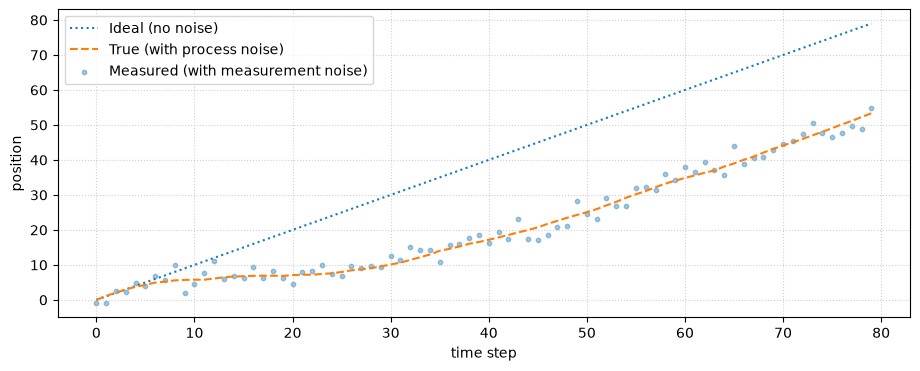

In [3]:
sample = kf.sample(80)                         # 80 steps of true state + measurements
t      = sample.time
true   = np.asarray(sample.xk)                 # the hidden true state
meas   = np.asarray(sample.zk)                 # what the sensor reports
ideal  = np.asarray(kf.model.ideal(duration=80))   # the noise-free reference

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, ideal[:, 0], ':',  label="Ideal (no noise)")
ax.plot(t, true[:, 0],  '--', label="Truth (with process noise)")
ax.scatter(t, meas[:, 0], s=10, alpha=0.4, label="Measured (with measurement noise)")
ax.set_xlabel("time step"); ax.set_ylabel("position")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

## 3 — How the filter works: **predict**, then **correct**

At every step the Kalman filter does two things:

1. **Predict** (using $F$ and $Q$): push the state estimate one step forward with the model, and **grow the
   uncertainty** (we are less sure after predicting blindly).
2. **Correct** (using the measurement, $H$ and $R$): blend the prediction with the new measurement. The blend
   weight is the **Kalman gain**: when the sensor is trustworthy the gain is high (follow the measurement);
   when it is noisy the gain is low (trust the model). After correcting, the **uncertainty shrinks**.

The filter tracks not just an estimate but a **covariance** — its own uncertainty. Below, the shaded band is
**± 3 standard deviations** (the square root of the covariance): wide when unsure, narrow when confident.
Notice **velocity is recovered even though only position is measured**.

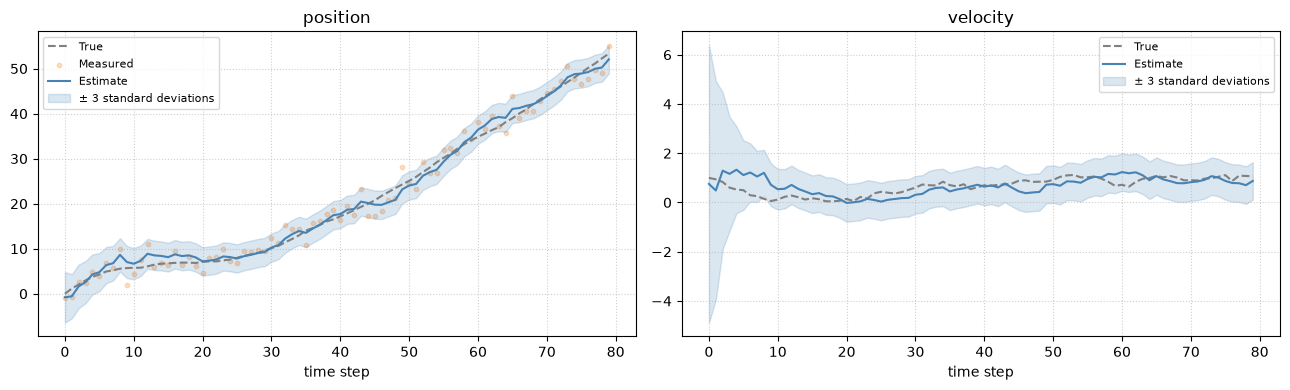

In [4]:
record = kf.filter(sample, reset=True)   # run the forward filter
est = np.asarray(record.xk)              # state estimate at each step
P   = np.asarray(record.Pk)              # covariance (uncertainty) at each step

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (ax, name) in enumerate(zip(axes, ["position", "velocity"])):
    sd = np.sqrt(P[:, i, i])             # standard deviation of this state
    ax.plot(t, true[:, i], '--', color='gray', label='Truth')
    if i == 0:
        ax.scatter(t, meas[:, 0], s=10, alpha=0.25, color='tab:orange', label='Measured')
    ax.plot(t, est[:, i], color='steelblue', label='Estimate')
    ax.fill_between(t, est[:, i] - 3*sd, est[:, i] + 3*sd, color='steelblue', alpha=0.2,
                    label='± 3 standard deviations')
    ax.set_title(name); ax.set_xlabel("time step"); ax.legend(fontsize=8); ax.grid(True, ls=':', alpha=0.6)
plt.tight_layout(); plt.show()

## 4 — Looking back: the smoother

The forward filter is **causal**: at step $k$ it has only seen measurements up to $k$. If you have the whole
recording in hand, you can do better. The **Rauch–Tung–Striebel smoother** (named after its three inventors)
adds a **backward pass** that also uses *future* measurements, improving every estimate and tightening the
uncertainty band — at the cost of needing all the data first (so it is for offline analysis, not real time).

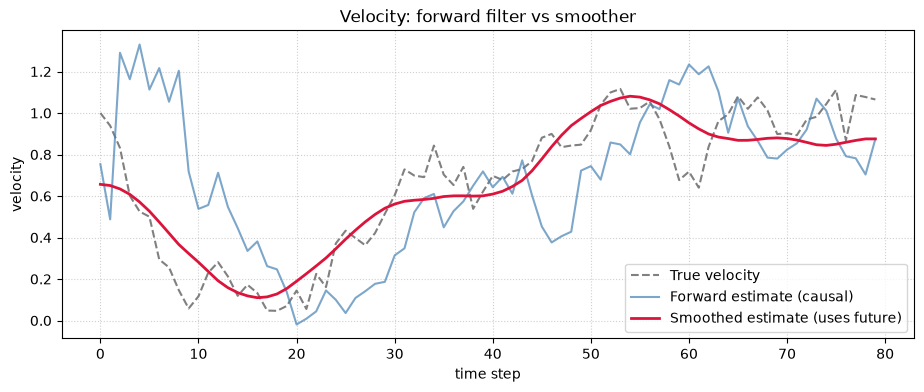

In [5]:
smoothed = kf.backward()                 # the backward (smoother) pass over the same run
sm = np.asarray(smoothed.xk)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, true[:, 1], '--', color='gray',      label='True velocity')
ax.plot(t, est[:, 1],        color='steelblue', alpha=0.7, label='Forward estimate (causal)')
ax.plot(t, sm[:, 1],         color='crimson',   lw=2,      label='Smoothed estimate (uses future)')
ax.set_title("Velocity: forward filter vs smoother")
ax.set_xlabel("time step"); ax.set_ylabel("velocity"); ax.legend(); ax.grid(True, ls=':', alpha=0.6); plt.show()

## 5 — Did it work? Checking the filter is *honest*

A filter is **consistent** when the errors it actually makes match the uncertainty it claims. Four standard checks:

- **Innovation (the measurement residual)** — the gap between the actual measurement and the measurement the
  filter predicted. It should hover around zero and stay (almost always, ~99.7%) inside its own
  ± 3-standard-deviation band.
- **Normalized Innovation Squared (NIS)** — the innovation squared, divided by its own predicted spread $S$.
  Its time-average should be about **$m$** (the number of measurements). It needs **no knowledge of the truth**,
  so it also works on real data.
- **Normalized Estimation Error Squared (NEES)** — the *actual* estimation error squared, divided by the claimed
  covariance $P$. Its time-average should be about **$n$** (the state dimension). It needs the true state (we have
  it in simulation). Much larger than $n$ ⇒ the filter is **over-confident**; much smaller ⇒ over-cautious.
- **Kalman gain over time** — how strongly each measurement corrects each state; it settles to a steady value
  (drawn on a log scale, since gains for different states often span orders of magnitude).

### Why "mean ≈ $m$" and "mean ≈ $n$"?

Both NIS and NEES take an error and **normalize it by the covariance the filter claims** for that error — NIS uses
the innovation $\nu$ and its covariance $S$ (forming $\nu^\top S^{-1}\nu$); NEES uses the estimation error
$e=x-\hat{x}$ and its covariance $P$ (forming $e^\top P^{-1}e$). That $\Sigma^{-1}$ **whitens** the error: it
rescales each direction by its own standard deviation, turning a $d$-dimensional Gaussian error into $d$
*independent standard normals*. The sum of their squares is a **chi-squared** with $d$ degrees of freedom, whose
expected value is exactly $d$:

$$\text{if } y\sim\mathcal{N}(0,\Sigma)\ \text{has length } d,\qquad
  y^\top\Sigma^{-1}y \sim \chi^2(d),\qquad \mathbb{E}\!\left[\,y^\top\Sigma^{-1}y\,\right]=d.$$

So **if the claimed covariance is honest**, NIS averages to the measurement dimension $m$ and NEES averages to the
state dimension $n$. The intuition without the maths: a value of **1 per dimension** means *"the errors are exactly
as big as the filter promised."* Summed over all dimensions you expect the dimension count — here **$m=1$** (one
position sensor) for NIS and **$n=2$** (position + velocity) for NEES. A single step is noisy; it is the
**time-average over the run** that converges to the target.


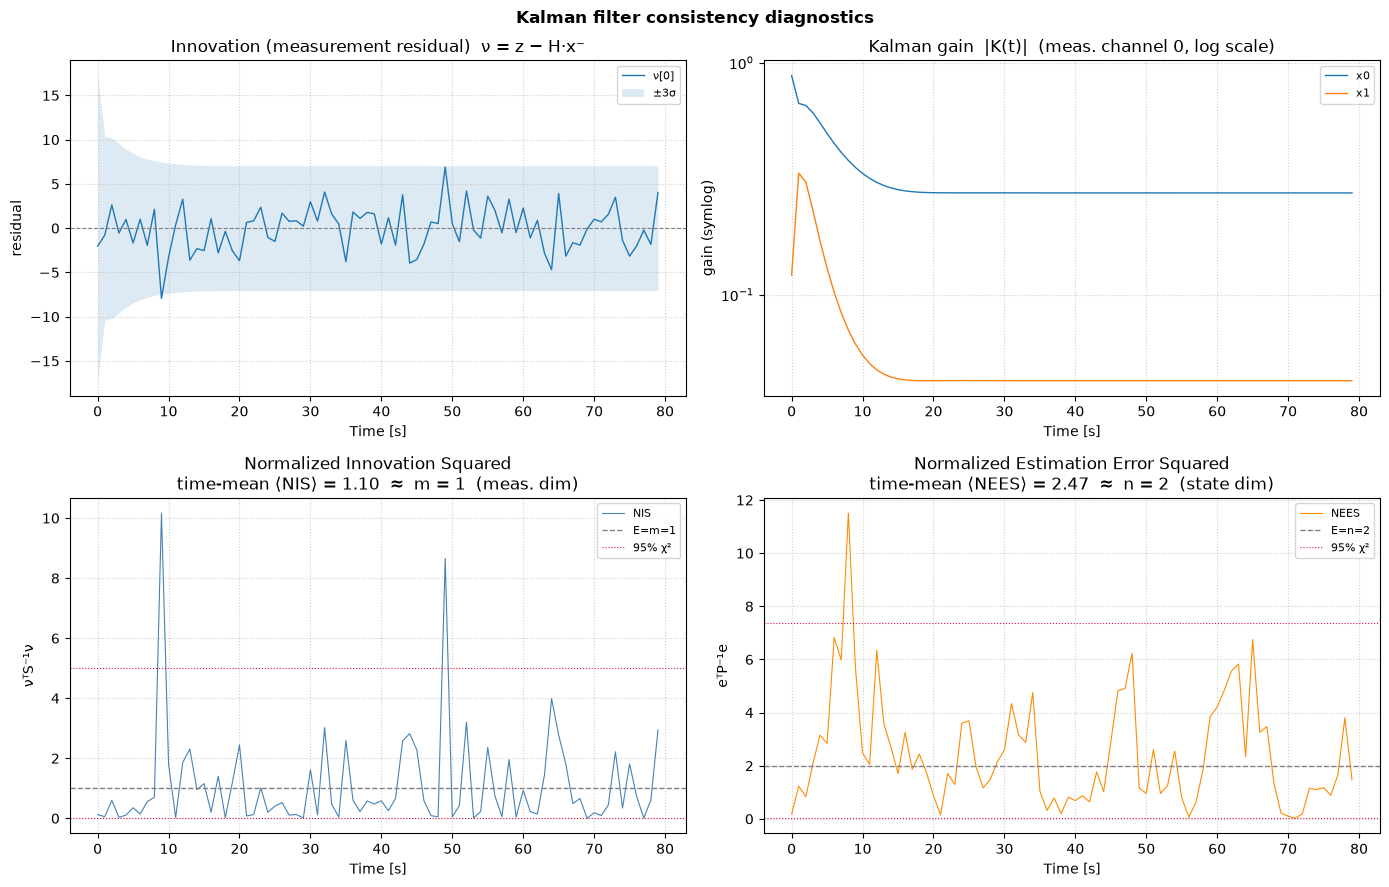

Normalized Innovation Squared,        mean = 1.10   (ideal ≈ m = 1)
Normalized Estimation Error Squared,  mean = 2.47   (ideal ≈ n = 2)


In [6]:
kf.filter(sample, reset=True)            # forward pass (diagnostics read it)
kf.diagnostics(sample=sample)            # innovation, gain, and the two consistency checks
plt.show()

print(f"Normalized Innovation Squared,        mean = {kf.nis().mean():.2f}   (ideal ≈ m = {kf.m})")
print(f"Normalized Estimation Error Squared,  mean = {kf.nees(sample.xk).mean():.2f}   (ideal ≈ n = {kf.n})")

## 6 — Changing the system = changing the matrices

Because the filter is *only* its four matrices, modelling a different system means **changing the matrices** —
nothing else. You can edit a coefficient in place (`kf.F = ...`, `kf.Q = ...`), or build a new filter.

As an example, suppose we add a **second sensor that also measures velocity**. We just give $H$ a second row
and $R$ a second entry, and set the measurement dimension `m = 2`:

In [7]:
kf2 = LinearKalmanFilter(
    n=2, m=2, fs=1.0,
    F=[[1, dt],[0, 1]],
    H=[[1, 0],            # sensor 1: position
       [0, 1]],           # sensor 2: velocity (new!)
    Q=[[0.01, 0],[0, 0.01]],
    R=[[4.0, 0   ],       # position-sensor variance
       [0,   0.25]],      # velocity-sensor variance (std 0.5)
    x0=[0, 1], P0=[[25, 0],[0, 4]], random_seed=1,
)
s2 = kf2.sample(80)
r1 = kf.filter(kf.sample(80), reset=True)        # position only (re-sampled)
r2 = kf2.filter(s2, reset=True)                  # position + velocity

err1 = np.sqrt(np.mean((np.asarray(r1.xk)[:, 1] - np.asarray(kf.model.ideal(duration=80))[:, 1])**2))
err2 = np.sqrt(np.mean((np.asarray(r2.xk)[:, 1] - np.asarray(kf2.model.ideal(duration=80))[:, 1])**2))
print(f"velocity error  — position sensor only : {err1:.3f}")
print(f"velocity error  — + velocity sensor    : {err2:.3f}   (smaller: more information)")

velocity error  — position sensor only : 0.510
velocity error  — + velocity sensor    : 0.463   (smaller: more information)


## 7 — Same machinery, a brand-new system: the Kalman filter *is* a low-pass

Nothing in the filter is specific to motion. To prove it, here is a completely different system built from the
**same four matrices and no special model class at all** — a single **drifting value** (a temperature, a voltage,
a slowly-changing calibration offset) read by a noisy sensor:

$$x_{k+1}=x_k+w_k\quad(\text{random walk}),\qquad z_k=x_k+v_k,$$

so $n=1$, $F=[1]$, $H=[1]$, $Q=[q^2]$, $R=[r^2]$. We will see the steady-state filter collapse into a textbook
**first-order low-pass** (an exponential moving average), and we will check it with the very same `.diagnostics()`.

Once the gain has converged, the Kalman update
$\;\mu_k=\mu_{k-1}+K\,(z_k-\mu_{k-1})=(1-K)\,\mu_{k-1}+K\,z_k\;$
is *exactly* an exponential moving average (EMA) with smoothing factor $\alpha=K_\mathrm{ss}$ and pole
$1-K_\mathrm{ss}$. For this scalar random walk the steady-state gain even has a closed form,
$\;K_\mathrm{ss}=\dfrac{\sqrt{q^4+4q^2r^2}-q^2}{2r^2}.$


steady-state Kalman gain  K_ss = 0.0488   (low-pass pole = 0.9512)
max |Kalman - low-pass| once converged: 4.44e-15


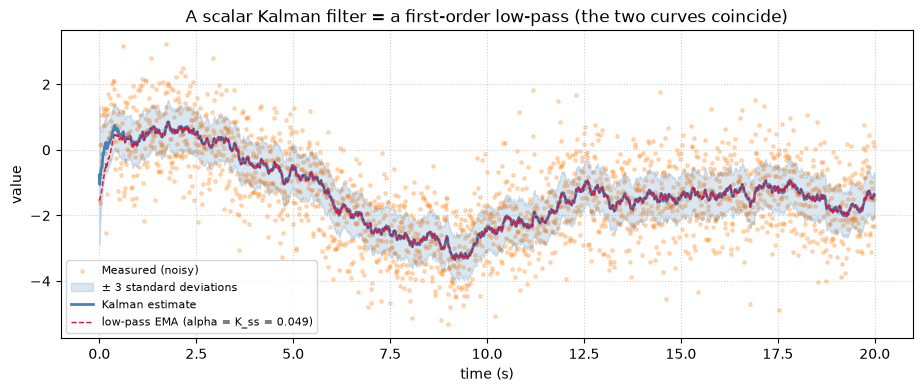

In [8]:
# A 1-state random-walk model — built from the SAME four matrices, no special class.
q, r = 0.05, 1.0                       # process std (how fast it drifts) and sensor std (noise)
lpkf = LinearKalmanFilter(
    n=1, m=1, fs=100.0,                # one state, one measurement, 100 samples per second
    F=[[1.0]],                         # random walk: the value stays put (plus process noise)
    H=[[1.0]],                         # the sensor reads the value directly
    Q=[[q**2]],                        # how fast the true value drifts
    R=[[r**2]],                        # how noisy the sensor is
    x0=[0.0], P0=[[1.0]], random_seed=0,
)
sig = lpkf.sample(20.0)                # 20 s @ 100 Hz of a drifting signal + noisy measurements
rec = lpkf.filter(sig, reset=True)

# Steady-state Kalman gain (closed form) and the equivalent exponential moving average:
K_ss = (np.sqrt(q**4 + 4*q**2*r**2) - q**2) / (2*r**2)
t  = sig.time
z  = np.asarray(sig.zk).ravel()
xk = np.asarray(rec.xk).ravel()
sd = np.sqrt(np.asarray(rec.Pk)[:, 0, 0])

ema = np.empty_like(z); ema[0] = z[0]
for k in range(1, len(z)):
    ema[k] = (1 - K_ss) * ema[k-1] + K_ss * z[k]     # mu = (1-K)mu + K z  — the KF update, verbatim
print(f"steady-state Kalman gain  K_ss = {K_ss:.4f}   (low-pass pole = {1-K_ss:.4f})")
print(f"max |Kalman - low-pass| once converged: {np.max(np.abs(xk[len(z)//2:] - ema[len(z)//2:])):.2e}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(t, z, s=6, alpha=0.25, color="tab:orange", label="Measured (noisy)")
ax.fill_between(t, xk - 3*sd, xk + 3*sd, color="steelblue", alpha=0.2, label="± 3 standard deviations")
ax.plot(t, xk,  color="steelblue", lw=2, label="Kalman estimate")
ax.plot(t, ema, color="crimson", lw=1, ls="--", label=f"low-pass EMA (alpha = K_ss = {K_ss:.3f})")
ax.set_xlabel("time (s)"); ax.set_ylabel("value"); ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.6)
ax.set_title("A scalar Kalman filter = a first-order low-pass (the two curves coincide)")
plt.show()


### The frequency view — and the only knob, $q/r$

Because the steady-state filter is a one-pole low-pass it has a frequency response $H$. Its complement $1-H$ is the
matching **high-pass**, so $\text{low}+\text{high}=z$ exactly — the filter just splits the signal at a **cutoff
frequency**. The ratio $q/r$ is the *only* thing that sets it: large $q$ (trust the data) ⇒ high cutoff, little
smoothing; small $q$ (trust the model) ⇒ low cutoff, heavy smoothing.


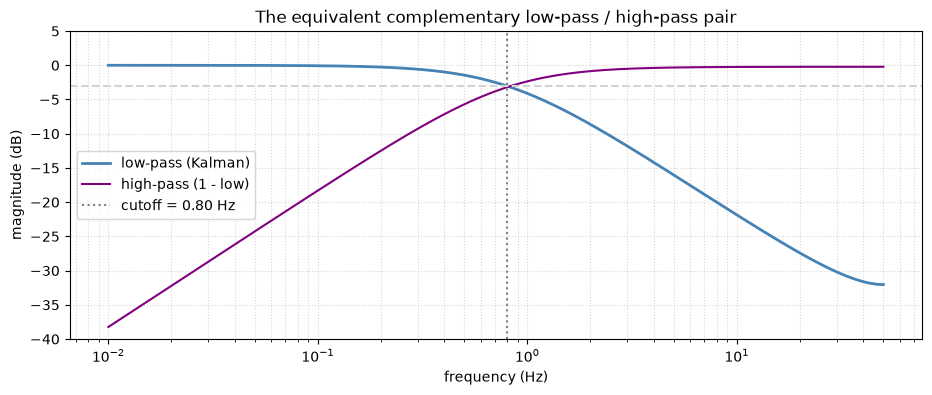

In [9]:
fs = 100.0
freqs = np.logspace(-2, np.log10(fs/2), 400)
w = 2*np.pi*freqs/fs
H = K_ss / (1 - (1 - K_ss)*np.exp(-1j*w))            # low-pass frequency response of the EMA
fc = freqs[np.argmin(np.abs(20*np.log10(np.abs(H)) + 3))]   # -3 dB cutoff

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogx(freqs, 20*np.log10(np.abs(H)),           color="steelblue", lw=2,   label="low-pass (Kalman)")
ax.semilogx(freqs, 20*np.log10(np.abs(1 - H) + 1e-12), color="purple",  lw=1.5, label="high-pass (1 - low)")
ax.axvline(fc, color="gray", ls=":", label=f"cutoff = {fc:.2f} Hz")
ax.axhline(-3, color="lightgray", ls="--")
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("magnitude (dB)"); ax.set_ylim(-40, 5)
ax.legend(); ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("The equivalent complementary low-pass / high-pass pair")
plt.show()


### Still honest — same diagnostics, a different system

The consistency checks from §5 do not care what the state *means*. Running the exact same `.diagnostics()` on this
one-state model gives a Normalized Innovation Squared that averages to $m=1$: the random-walk low-pass is just as
well-calibrated as the motion tracker — strong evidence that the Kalman filter is genuinely **model-agnostic**.


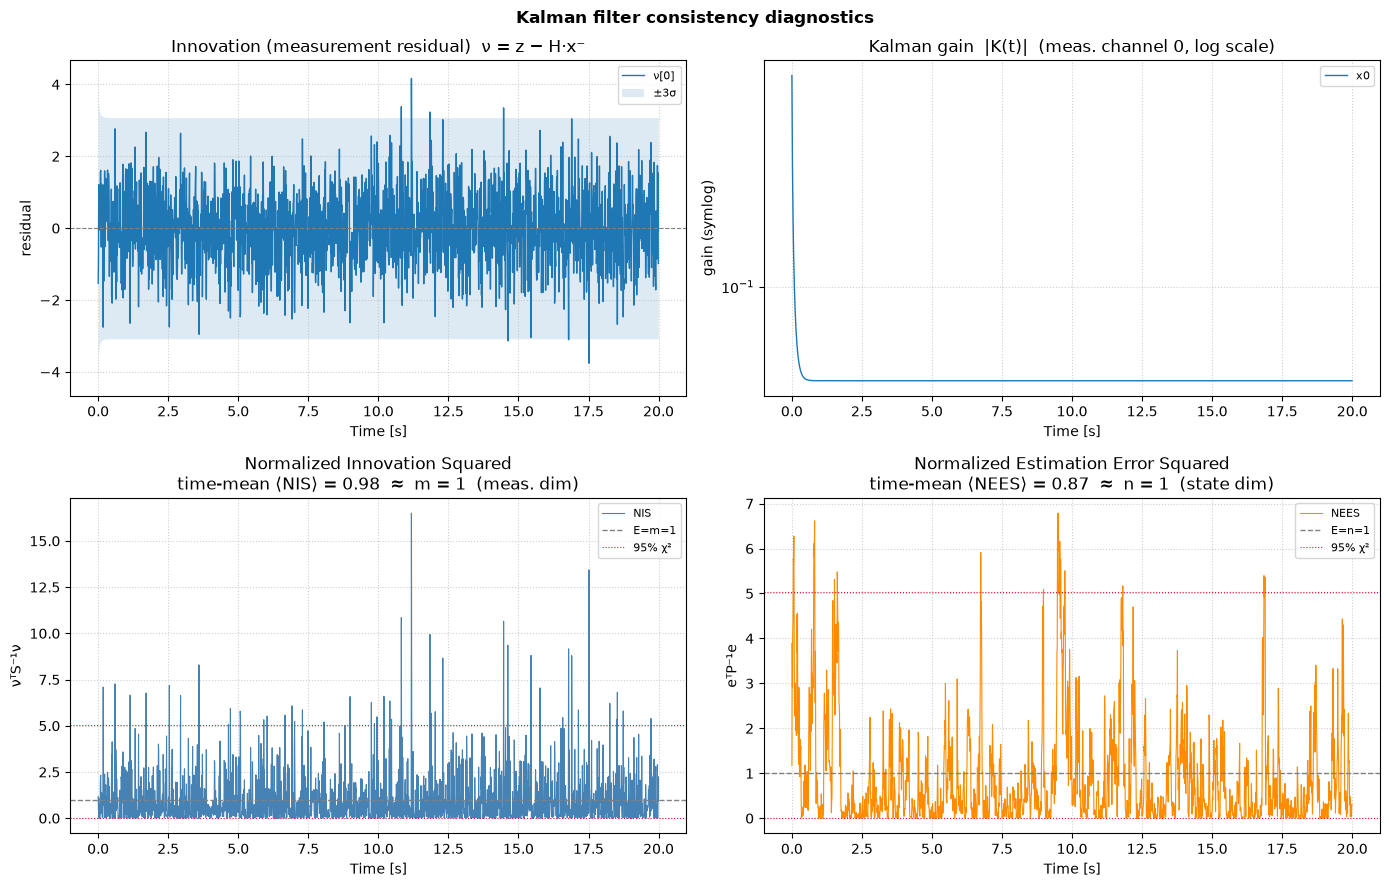

Normalized Innovation Squared, mean = 0.98   (ideal ~ m = 1)


In [10]:
lpkf.filter(sig, reset=True)
lpkf.diagnostics(sample=sig)          # the very same dashboard — model-agnostic
plt.show()
print(f"Normalized Innovation Squared, mean = {lpkf.nis().mean():.2f}   (ideal ~ m = {lpkf.m})")


### From one low-pass to a high-pass and a band-pass

The same exponential moving average is a whole filter toolkit. Write `lp(z, f_c)` for the EMA whose −3 dB cutoff
is `f_c` (smoothing factor `α = 1 − e^(−2π f_c / f_s)`). Then

- **low-pass** = `lp(z, f_c)` — keep everything **below** `f_c`;
- **high-pass** = `z − lp(z, f_c)` — keep everything **above** `f_c` (the complement we just saw on the Bode plot);
- **band-pass** = `lp(z, f_high) − lp(z, f_low)` — subtract a slow low-pass from a fast one to keep the **band** in between.

Below, a signal made of a slow drift (0.3 Hz), a mid tone (5 Hz) and a fast tone + noise (30 Hz) is separated into
its three bands by exactly these one-line filters.


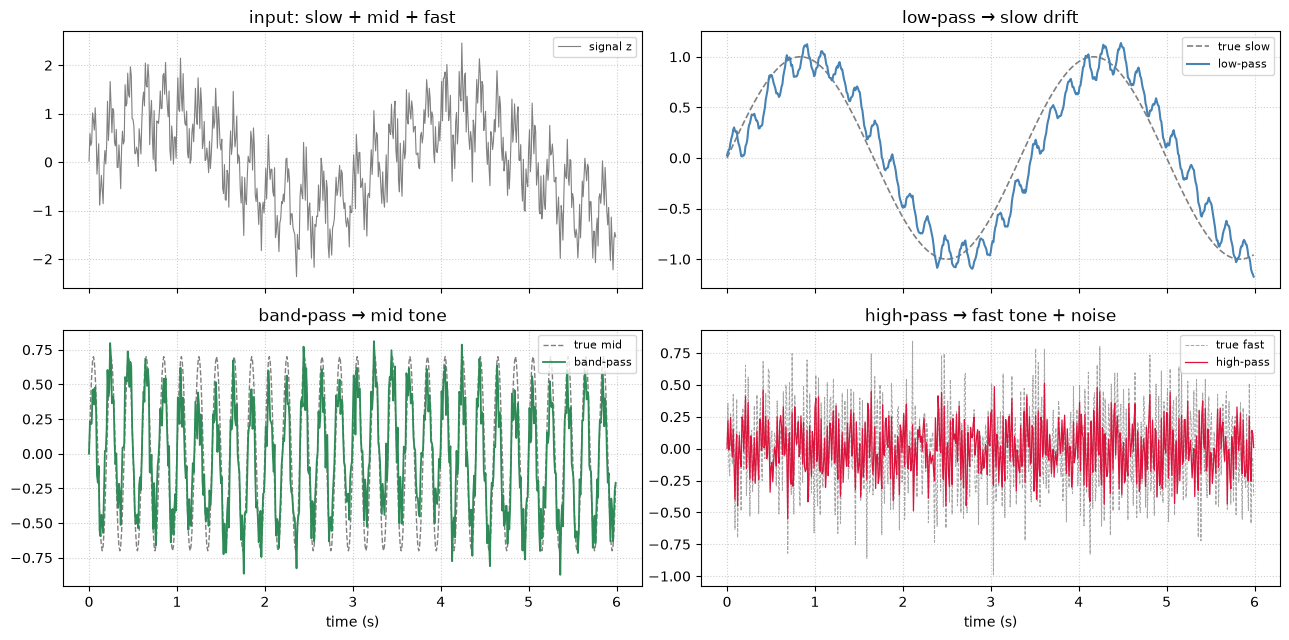

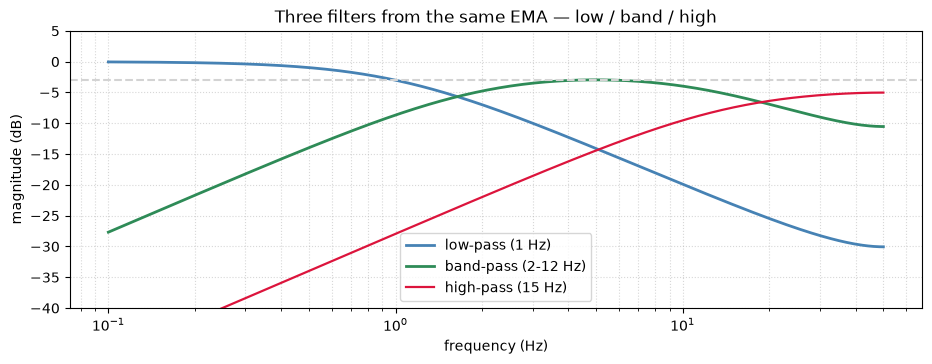

In [11]:
# A 3-band test signal: slow drift + mid tone + fast tone & noise.
fs_b = 100.0
tb = np.arange(0, 6.0, 1/fs_b)
rng = np.random.default_rng(0)
slow = 1.0*np.sin(2*np.pi*0.3*tb)                                      # ~0.3 Hz  (low band)
mid  = 0.7*np.sin(2*np.pi*5.0*tb)                                      # ~5 Hz    (mid band)
fast = 0.4*np.sin(2*np.pi*30.0*tb) + 0.2*rng.standard_normal(tb.size)  # ~30 Hz + noise (high band)
zb = slow + mid + fast

def ema(x, alpha):                          # first-order low-pass (exponential moving average)
    y = np.empty_like(x); acc = x[0]
    for k in range(len(x)):
        acc = (1 - alpha)*acc + alpha*x[k]; y[k] = acc
    return y
alpha_for = lambda fc: 1.0 - np.exp(-2*np.pi*fc/fs_b)                  # EMA smoothing for a -3 dB cutoff fc

low_pass  = ema(zb, alpha_for(1.0))                                    # keep < ~1 Hz
high_pass = zb - ema(zb, alpha_for(15.0))                             # keep > ~15 Hz
band_pass = ema(zb, alpha_for(12.0)) - ema(zb, alpha_for(2.0))       # keep ~2..12 Hz

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
ax[0,0].plot(tb, zb, color="gray", lw=0.8, label="signal z"); ax[0,0].set_title("input: slow + mid + fast")
ax[0,1].plot(tb, slow, color="gray", lw=1.2, ls="--", label="true slow")
ax[0,1].plot(tb, low_pass, color="steelblue", lw=1.5, label="low-pass"); ax[0,1].set_title("low-pass → slow drift")
ax[1,0].plot(tb, mid, color="gray", lw=1.0, ls="--", label="true mid")
ax[1,0].plot(tb, band_pass, color="seagreen", lw=1.3, label="band-pass"); ax[1,0].set_title("band-pass → mid tone")
ax[1,1].plot(tb, fast, color="gray", lw=0.7, ls="--", alpha=0.7, label="true fast")
ax[1,1].plot(tb, high_pass, color="crimson", lw=0.9, label="high-pass"); ax[1,1].set_title("high-pass → fast tone + noise")
for a in ax.ravel(): a.grid(True, ls=":", alpha=0.6); a.legend(fontsize=8, loc="upper right")
for a in ax[1]: a.set_xlabel("time (s)")
plt.tight_layout(); plt.show()

# Frequency view: the three filters built from the same EMA.
freqs = np.logspace(-1, np.log10(fs_b/2), 400); wq = 2*np.pi*freqs/fs_b
Hema  = lambda fc: alpha_for(fc) / (1 - (1 - alpha_for(fc))*np.exp(-1j*wq))
Hlow, Hhigh, Hband = Hema(1.0), 1 - Hema(15.0), Hema(12.0) - Hema(2.0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.semilogx(freqs, 20*np.log10(np.abs(Hlow)),          color="steelblue", lw=2,   label="low-pass (1 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(Hband) + 1e-12), color="seagreen",  lw=2,   label="band-pass (2-12 Hz)")
ax.semilogx(freqs, 20*np.log10(np.abs(Hhigh) + 1e-12), color="crimson",   lw=1.6, label="high-pass (15 Hz)")
ax.axhline(-3, color="lightgray", ls="--"); ax.set_ylim(-40, 5)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("magnitude (dB)")
ax.legend(); ax.grid(True, which="both", ls=":", alpha=0.5)
ax.set_title("Three filters from the same EMA — low / band / high")
plt.show()


## 8 — Closing the loop: control

Every section so far has been **open-loop**: the filter received measurements and produced an estimate, but that
estimate never fed back into the world. **Control** closes this loop.

A **controller** reads the filter's latest estimate $\hat{\mathbf{x}}$ and outputs a **control signal** $u$ that
nudges the physical system toward a target $x_\text{ref}$:

```
    x_ref
      │
      ▼
 u = ctrl(x̂) ──► physical system ──► z ──► filter ──► x̂
      ◄──────────────────────────────────────────────────┘
```

The only change to the filter's equations is **one extra matrix, $B$**, which says how control enters the state:

$$\mathbf{x}_{k} = F\,\mathbf{x}_{k-1} \;+\; B\,u_{k-1} \;+\; w_k .$$

Everything else — $F$, $H$, $Q$, $R$, the gain, the uncertainty — is unchanged.

Passing `uk=ctrl` to `forward()` (where `ctrl` is any callable `(x̂, P, t, ν) → u`) runs the closed loop
automatically: at each step the filter evaluates `u = ctrl(x̂, P, t, ν)` **before predict**, so the prediction
already accounts for the applied input.

Below we take the §7 random-walk model and add $B = [1]$ (control directly shifts the value). A simple
**proportional** controller, $u = -K_p\,(\hat{x} - x_\text{ref})$, drives the value from 0 to the target 5.0.
For full applications — car lane-keeping, LQR, and a neural policy trained on the filter's own physics model —
see **`12_KalmanAI.ipynb`**.

In [ ]:
# Take the §7 random-walk model and add B = [1]:  x(k) = F·x(k-1) + B·u(k-1) + noise
kfc = LinearKalmanFilter(
    n=1, m=1, fs=1.0,
    F=[[1.0]], H=[[1.0]], B=[[1.0]],   # same as §7, plus B
    Q=[[0.05**2]], R=[[1.0]],          # same noise parameters as §7
    x0=[[0.0]],
)

x_ref = 5.0   # target value
Kp    = 0.5   # proportional gain:  u = -Kp · (x̂ − x_ref)

N = 60; rng_ctrl = np.random.default_rng(42)
x_true_c = np.array([[0.0]])
pos_true, pos_est, u_hist = [], [], []

for k in range(N):
    # ── controller reads filter estimate, computes u ─────────────────────
    u  = -Kp * (kfc.x[0, 0] - x_ref)
    uk = np.array([[u]])

    # ── truth: the physical system responds to the *actual* control u ────
    x_true_c = np.array([[1.0]]) @ x_true_c + np.array([[1.0]]) @ uk \
               + rng_ctrl.normal(0, 0.05, (1, 1))
    z = np.array([[x_true_c[0, 0] + rng_ctrl.normal(0, 1.0)]])

    # ── one filter step ───────────────────────────────────────────────────
    kfc.forward(z, uk=uk, reset=(k == 0))

    pos_true.append(x_true_c[0, 0])
    pos_est.append(kfc.x[0, 0])
    u_hist.append(u)

tk = np.arange(N)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.axhline(x_ref, color="k", ls="--", lw=0.8, label=f"target  x_ref = {x_ref}")
ax.plot(tk, pos_true, color="gray",      lw=1.2, label="True value")
ax.plot(tk, pos_est,  color="steelblue", lw=1.5, label="Estimate x̂")
ax.set_title("Value controlled toward target"); ax.set_xlabel("time step")
ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.6)

ax = axes[1]
ax.plot(tk, u_hist, color="seagreen", lw=1.2)
ax.axhline(0, color="k", ls="--", lw=0.5)
ax.set_title(r"Control signal  $u = -K_p\,(\hat{x} - x_{\rm ref})$"); ax.set_xlabel("time step")
ax.grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()
print(f"Final true value: {pos_true[-1]:.2f}   (target {x_ref},  residual = {pos_true[-1]-x_ref:+.2f})")

## Summary & where to go next

| Idea | Section |
|---|---|
| A system is four matrices: $F$, $H$, $Q$, $R$ | §1 |
| Ideal vs true vs measured data | §2 |
| Predict + correct, the Kalman gain, the uncertainty band | §3 |
| The Rauch–Tung–Striebel smoother (uses future data) | §4 |
| Consistency: innovation, and the two normalized checks | §5 |
| Change the system by changing the matrices | §6 |
| A new system: a scalar low-pass (= EMA), and high-pass & band-pass from it | §7 |
| Add $B$ to close the loop: a controller drives the system to $x_\text{ref}$ | §8 |

When the system is **not** linear — the state moves through curved dynamics, or the sensor relates to the
state nonlinearly — the same predict/correct idea still works through the **Extended Kalman filter**
(linearises each step) or the **Unscented Kalman filter** (propagates a cloud of sample points). For very
non-Gaussian problems there is the **particle filter**.

➡️ **`01_Ballistics.ipynb`** puts all of this to work on a real, three-dimensional, nonlinear problem
(a projectile under gravity and air drag), and compares these filters head to head.

➡️ For the frequency-domain companions to §7 — the **Wiener** filter, the complementary high-pass, and the
`pull` / `error_ratio` consistency diagnostics — see the standalone helpers in **`kalman.runtime.signals`**.

➡️ **`12_KalmanAI.ipynb`** extends §8 into the first full AI-controlled Kalman application: car lane-keeping
with proportional, PID, LQR, and a neural policy trained on the filter's own physics model.